# Overview

Based on the official transverse-field Ising model (TFIM) simulation tutorial, this notebook investigates how does the max error of magnetization change with different values of trotter step $\Delta t$, explored error scaling, compares the first-order Lie-Trotter and second-order Suzuki-Trotter, and studies the trade-off of the max error values and total amount of two-qubit gates.

# Base Model

First, we import the required libraries.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
from adjustText import adjust_text

from qiskit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator

The Hamiltonian of transverse-field Ising model (TFIM) is given by
$$
\hat{H} = -J \sum_{i=0}^{N-2} Z_i Z_{i+1} \; - \; h \sum_{i=0}^{N-1} X_i
$$

The code from the official challenge 3 tutorial is used to define the Hamiltonian. Same as in the tutorial, a chain of $N = 4$ spins with coupling $J = 1$ and field $h = 1$ is considered to keep the model simple.

In [16]:
def tfim_hamiltonian(num_qubits, J=1.0, h=1.0):
    """Transverse-field Ising Hamiltonian on an open chain as a SparsePauliOp."""
    terms = []

    # Interaction terms: -J * Z_i Z_{i+1}
    for i in range(num_qubits - 1):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        pauli[i + 1] = "Z"
        # Qiskit reads Pauli strings right-to-left (qubit 0 is the rightmost char)
        terms.append(("".join(reversed(pauli)), -J))

    # Field terms: -h * X_i
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), -h))

    return SparsePauliOp.from_list(terms)


num_qubits = 4
J, h = 1.0, 1.0
H = tfim_hamiltonian(num_qubits, J, h)

print(f"TFIM on {num_qubits} qubits (J={J}, h={h}):")
print(H)

TFIM on 4 qubits (J=1.0, h=1.0):
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])


Note that here we first append the interaction terms (the ones with Pauli $Z$ matrices) and then the field terms (the ones with Pauli $X$ matrices). This will have an effect later.

The averaged total magnetization along $z$ axis is
$$
M_z(t) = \frac{1}{N}\sum_{i=0}^{N-1} \langle \psi(t) | Z_i | \psi(t)\rangle.
$$

The code from the official tutorial below constructs trotter evolution circuit and magnetization operator along $z$. The initial state is the defult $|00 \dots 0 \rangle$.

In [17]:
def trotter_evolution_circuit(H, num_qubits, dt, n_steps, order):
    """Prepare |00..0> and apply n_steps Trotter steps of size dt."""
    if order == 1:
        synth = LieTrotter(reps=1)
    else:
        synth = SuzukiTrotter(order=order, reps=1)

    qc = QuantumCircuit(num_qubits)
    # initial state |00..0> is the default; add an explicit barrier for clarity
    qc.barrier()

    step = PauliEvolutionGate(H, time=dt, synthesis=synth)
    # for _ in range(n_steps):
            #     qc.append(step, range(num_qubits))

    #Above is the original code from the tutorial, but I found that it actually produces a result we didn't want (at least on my laptop).
    #If we do not synthesize manually, PauliEvolutionGate will use the exact matrix form instead of doing trotterlization
    #resulting in extremely low errors (around 10^-15) regardless of the value of dt
    #So we manually wrote synthesize here
    trotter_step = synth.synthesize(step)
    for _ in range(n_steps):
            qc.append(trotter_step, range(num_qubits))

    qc_d=qc.decompose(reps=2)
    # print(f"One Trotter step (dt={0.2}):  depth = {qc.depth()}, "
    # f"2-qubit gates = {qc.num_nonlocal_gates()}")
    two_qubit_gates = qc_d.num_nonlocal_gates()
    
    return qc, two_qubit_gates

def z_magnetization_op(num_qubits):
    """(1/N) * sum_i Z_i as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "Z"
        terms.append(("".join(reversed(pauli)), 1.0 / num_qubits))
    return SparsePauliOp.from_list(terms)


Mz = z_magnetization_op(num_qubits)
estimator = StatevectorEstimator()

Then, we carry out trotterized time evolution.

Eight $\Delta t$ values ranging from 0.05 to 0.50 are used. The total evolution time is fixed at 6.0 seconds for better comparison. Values of 0.35 and 0.45 are excluded because 6.0 is not divisible by them. The values of max error in $z$ magnetization and total amount of two-qubit gates for each value of $\Delta t$ is calculated and stored. The trotter values, exact solution, and the max error are then plotted for different values of $\Delta t$.

In [18]:
# first-order Mz
dt_list = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
max_error_lie = []
two_qubit_gates_lie = []
frames = []

for i, dt in enumerate(dt_list):
    # --- Trotterized evolution ---
    max_steps = round(6.0 / dt)  #fixed time interval = 6.0 seconds
    times = np.array([n * dt for n in range(max_steps + 1)])

    mz_trotter = []
    two_qubit_gates_temp = 0
    for n in range(max_steps + 1):
        circ, two_qubit_gates_temp = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n, order=1)
        result = estimator.run([(circ, Mz)]).result()
        mz_trotter.append(float(result[0].data.evs))
    mz_trotter = np.array(mz_trotter)

    # --- Exact reference evolution (classical, small systems only) ---
    from scipy.linalg import expm

    H_matrix = H.to_matrix()
    Mz_matrix = Mz.to_matrix()
    psi0 = Statevector.from_label("0" * num_qubits).data

    mz_exact = []
    for t in times:
        U = expm(-1j * H_matrix * t)
        psi_t = U @ psi0
        val = np.real(np.conj(psi_t) @ Mz_matrix @ psi_t)
        mz_exact.append(val)
    mz_exact = np.array(mz_exact)

    max_error_lie.append(np.max(np.abs(mz_trotter - mz_exact)))
    two_qubit_gates_lie.append(two_qubit_gates_temp)

    frames.append({
        "dt": dt,
        "times": times,
        "mz_exact": mz_exact,
        "mz_trotter": mz_trotter
    })

    print(f"dt: {dt}")
    print(f"Max error over the trajectory: {max_error_lie[i]:.5f}")
    print(f"Total Amount of Two-Qubit Gates: {two_qubit_gates_lie[i]}")

dt: 0.05
Max error over the trajectory: 0.00438
Total Amount of Two-Qubit Gates: 720
dt: 0.1
Max error over the trajectory: 0.01759
Total Amount of Two-Qubit Gates: 360
dt: 0.15
Max error over the trajectory: 0.03948
Total Amount of Two-Qubit Gates: 240
dt: 0.2
Max error over the trajectory: 0.07143
Total Amount of Two-Qubit Gates: 180
dt: 0.25
Max error over the trajectory: 0.10997
Total Amount of Two-Qubit Gates: 144
dt: 0.3
Max error over the trajectory: 0.16477
Total Amount of Two-Qubit Gates: 120
dt: 0.4
Max error over the trajectory: 0.29434
Total Amount of Two-Qubit Gates: 90
dt: 0.5
Max error over the trajectory: 0.44943
Total Amount of Two-Qubit Gates: 72


In [19]:
# --- Create Graph Animation ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                            gridspec_kw={"height_ratios": [3, 1]})
plt.tight_layout()

def update(i):
    ax1.clear()
    ax2.clear()

    data = frames[i]
    dt = data["dt"]
    times = data["times"]
    mz_exact = data["mz_exact"]
    mz_trotter = data["mz_trotter"]

    ax1.plot(times, mz_exact, "k-", lw=2, label="Exact")
    ax1.plot(times, mz_trotter, "o--", color="#1f77b4", ms=4,
             label=f"Trotter (1st order, dt={dt})")
    ax1.set_ylabel(r"Magnetization  $M_z(t)$")
    ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(times, np.abs(mz_trotter - mz_exact), color="#d62728")
    ax2.set_xlabel("Time  t")
    ax2.set_ylabel("abs. error")
    ax2.grid(alpha=0.3)

    return ax1, ax2

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=1000,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

We can see that as $\Delta t$ increases, the approximation becomes increasingly rough, and the overall error rises. It is also clear from the graph that the trotterized curve lags further and further behind the exact solution as time progresses.

Before looking into the relationship between the max error in $z$ magnetization and the total amount of two-qubit gates, let's first see if the error scaling appears as expected.

# Error Scaling

In first-order Lie-Trotterization, the local approximation error scales as $O(\Delta t^2)$ for non-commuting Hamiltonian terms. [1] This conclusion can be derived from the Baker–Campbell–Hausdorff formula.

Let the total evolution time be $T$, divided into $n$ steps. Then $\Delta t=\frac{T}{n}$.

Since the local error scaling (error for a single trotter step) is $O(\Delta t^2)$, The accumulated total error after $n$ steps would be $O(n\Delta t^2) = O(T\Delta t)$.

Therefore, when $T$ is fixed, the total error should scale linearly with $\Delta t$. To put it in another way, if we plot log(max error) against log(dt), the slope should be approximately 1.

Let's check if that's the case.

Slope = 2.018701676246663


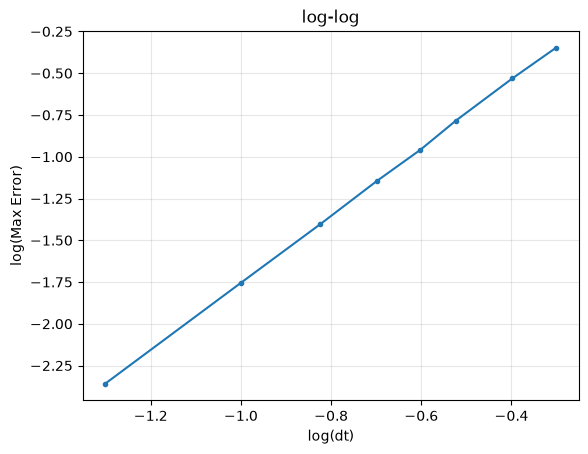

In [20]:
# first-order
logx = np.log10(dt_list)
logy = np.log10(max_error_lie)
loglog_slope=np.polyfit(logx, logy, deg=1)[0]
print("Slope =", loglog_slope)

plt.title("log-log")
plt.xlabel("log(dt)")
plt.ylabel("log(Max Error)")
plt.grid(alpha=0.3)
plt.plot(logx, logy, marker=".")
plt.show()

It turns out that the result is not what we expected. The slope is approximately 2, suggesting a total error scaling of $O(\Delta t^2)$ and a second-order trotterization. Why?

The reason behind this lies in the commutative properties of the operators.

Recall the formula of first-order Lie-Trotterization:
$$
e^{-i\hat{H}t} \approx \left( e^{-i\hat{H}_{X}\Delta t} \; e^{-i\hat{H}_{ZZ}\Delta t} \right)^{n}
$$
and the formula of second-order Suzuki Trotterization:
$$
e^{-i\hat{H}t} \approx \left(e^{-i\hat{H}_{ZZ}\Delta t/2} \; e^{-i\hat{H}_{X}\Delta t} \; e^{-i\hat{H}_{ZZ}\Delta t/2} \right)^{n}
$$

Note that since the Hamiltonian we constructed earlier first applies the term with $\hat{H}_{ZZ}$, this term appears on the rightmost side of the formula for both Lie-Trotter and Suzuki-Trotter.

We can denote a single step of first-order Lie-Trotterization as $U_L$ and a single step of second-order Suzuki-Trotterization as $U_S$. Then, we can see that they have the following relationship:
$$
U_L = e^{i\hat{H}_{ZZ}\Delta t/2} \; U_S \; e^{-i\hat{H}_{ZZ}\Delta t/2}
$$

In our case, the initial state is $| 00 \dots 0 \rangle$. After $n$ steps of first-order Lie-Trotter evolution, this state becomes
$$
|\psi_n\rangle
=
U_L^n \; | 00 \dots 0 \rangle
=
 e^{i\hat{H}_{ZZ}\Delta t/2} \; U_S^n \; e^{-i\hat{H}_{ZZ}\Delta t/2} \; | 00 \dots 0 \rangle
$$

Since $| 00 \dots 0 \rangle$ is an eigenstate of Pauli Z matrices, $e^{-i\hat{H}_{ZZ}\Delta t/2} \; | 00 \dots 0 \rangle$ would simply yield a global phase, say $e^{-i\theta}$, which can be canceled out when calculating the average total $z$ magnetization.

So, the averaged total magnetization along $z$ for our state using the first-order Lie-Trotterization is
$$
\begin{align*}
M_z(t) &= \frac{1}{N}\sum_{i=0}^{N-1} \; \langle 00 \dots 0 | {U_L^\dagger}^n | Z_i | U_L^n | 00 \dots 0 \rangle
\\
&= \frac{1}{N}\sum_{i=0}^{N-1} \;
\langle 00 \dots 0 |
e^{i\theta} \; {U_S^\dagger}^n \; e^{-i\hat{H}_{ZZ}\Delta t/2}\; 
Z_i \;
e^{i\hat{H}_{ZZ}\Delta t/2} \; U_S^n \; e^{-i\theta}
| 00 \dots 0 \rangle
\\
&= \frac{1}{N}\sum_{i=0}^{N-1} \;
\langle 00 \dots 0 |
 {U_S^\dagger}^n \; e^{-i\hat{H}_{ZZ}\Delta t/2}\; 
Z_i \;
e^{i\hat{H}_{ZZ}\Delta t/2} \; U_S^n
| 00 \dots 0 \rangle
\end{align*}
$$

Since $e^{-i\hat{H}_{ZZ}\Delta t}$ is composed of all $Z$ matrices, and $Z$ matrices are diagonal matrices, it can commute with $Z_i$. Therefore, $e^{-i\hat{H}_{ZZ}\Delta t}$ and $e^{i\hat{H}_{ZZ}\Delta t}$ canceled out, and what remains is
$$
M_z(t)
=
\frac{1}{N}\sum_{i=0}^{N-1} \;
\langle 00 \dots 0 |
 {U_S^\dagger}^n \;
Z_i \;
U_S^n
| 00 \dots 0 \rangle
$$

This is the exact same form if we use the second-order Suzuki-Trotterization.

Therefore, for our initial state of $| 00 \dots 0 \rangle$ and our magnetization observable along $z$ axis, the first-order Lie-Trotterization and the second-order Suzuki-Trotterization are mathematically identical. This can explain why we got a slope of 2 instead of 1.

To verify this, we can choose a different initial state that is not the eigenstate of Pauli Z matrices, or change an observable that does not commute with $Z_i$. Here we adopt the latter method.

The code below is an adjustment of the previous code to construct the averaged total magnetization along $x$ axis.

$$
M_x(t) = \frac{1}{N}\sum_{i=0}^{N-1} \langle \psi(t) | X_i | \psi(t)\rangle.
$$

In [21]:
def x_magnetization_op(num_qubits):
    """(1/N) * sum_i X_i as a SparsePauliOp."""
    terms = []
    for i in range(num_qubits):
        pauli = ["I"] * num_qubits
        pauli[i] = "X"
        terms.append(("".join(reversed(pauli)), 1.0 / num_qubits))
    return SparsePauliOp.from_list(terms)


Mx = x_magnetization_op(num_qubits)
estimator = StatevectorEstimator()

Then we run the trotterized evolution again. This time we measure $x$ magnetization.

In [22]:
# first-order Mx
max_error_lie = []
two_qubit_gates_lie = []
frames = []

for i, dt in enumerate(dt_list):
    # --- Trotterized evolution ---
    max_steps = round(6.0 / dt)  #fixed time interval = 6.0 seconds
    times = np.array([n * dt for n in range(max_steps + 1)])

    mx_trotter = []
    two_qubit_gates_temp = 0
    for n in range(max_steps + 1):
        circ, two_qubit_gates_temp = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n, order=1)
        result = estimator.run([(circ, Mx)]).result()
        mx_trotter.append(float(result[0].data.evs))
    mx_trotter = np.array(mx_trotter)

    # --- Exact reference evolution (classical, small systems only) ---
    from scipy.linalg import expm

    H_matrix = H.to_matrix()
    Mx_matrix = Mx.to_matrix()
    psi0 = Statevector.from_label("0" * num_qubits).data

    mx_exact = []
    for t in times:
        U = expm(-1j * H_matrix * t)
        psi_t = U @ psi0
        val = np.real(np.conj(psi_t) @ Mx_matrix @ psi_t)
        mx_exact.append(val)
    mx_exact = np.array(mx_exact)

    max_error_lie.append(np.max(np.abs(mx_trotter - mx_exact)))
    two_qubit_gates_lie.append(two_qubit_gates_temp)

    frames.append({
        "dt": dt,
        "times": times,
        "mx_exact": mx_exact,
        "mx_trotter": mx_trotter
    })

    print(f"dt: {dt}")
    print(f"Max error over the trajectory: {max_error_lie[i]:.5f}")
    print(f"Total Amount of Two-Qubit Gates: {two_qubit_gates_lie[i]}")

dt: 0.05
Max error over the trajectory: 0.03223
Total Amount of Two-Qubit Gates: 720
dt: 0.1
Max error over the trajectory: 0.07110
Total Amount of Two-Qubit Gates: 360
dt: 0.15
Max error over the trajectory: 0.11142
Total Amount of Two-Qubit Gates: 240
dt: 0.2
Max error over the trajectory: 0.16430
Total Amount of Two-Qubit Gates: 180
dt: 0.25
Max error over the trajectory: 0.22782
Total Amount of Two-Qubit Gates: 144
dt: 0.3
Max error over the trajectory: 0.30052
Total Amount of Two-Qubit Gates: 120
dt: 0.4
Max error over the trajectory: 0.42260
Total Amount of Two-Qubit Gates: 90
dt: 0.5
Max error over the trajectory: 0.62367
Total Amount of Two-Qubit Gates: 72


In [23]:
# --- Create Graph Animation ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                            gridspec_kw={"height_ratios": [3, 1]})
plt.tight_layout()

def update(i):
    ax1.clear()
    ax2.clear()

    data = frames[i]
    dt = data["dt"]
    times = data["times"]
    mx_exact = data["mx_exact"]
    mx_trotter = data["mx_trotter"]

    ax1.plot(times, mx_exact, "k-", lw=2, label="Exact")
    ax1.plot(times, mx_trotter, "o--", color="#1f77b4", ms=4,
             label=f"Trotter (1st order, dt={dt})")
    ax1.set_ylabel(r"Magnetization  $M_x(t)$")
    ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(times, np.abs(mx_trotter - mx_exact), color="#d62728")
    ax2.set_xlabel("Time  t")
    ax2.set_ylabel("abs. error")
    ax2.grid(alpha=0.3)

    return ax1, ax2

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=1000,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

By the way, we can see that the patterns we summarized earlier are still true after changing the observable: the overall error increases as $\Delta t$ increases, and the change in our approximation is delayed.

Slope = 1.2822389851416147


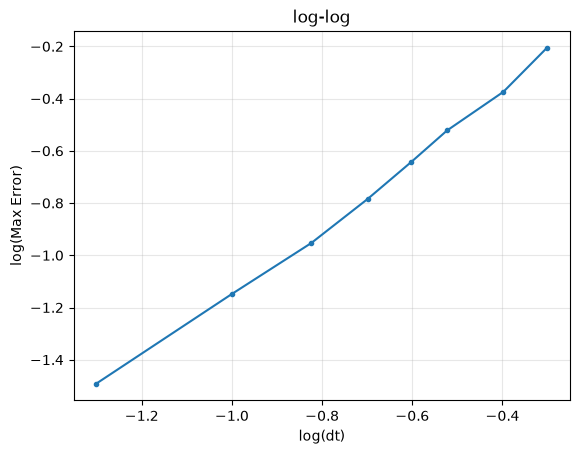

In [24]:
# first-order
logx = np.log10(dt_list)
logy = np.log10(max_error_lie)
loglog_slope=np.polyfit(logx, logy, deg=1)[0]
print("Slope =", loglog_slope)

plt.title("log-log")
plt.xlabel("log(dt)")
plt.ylabel("log(Max Error)")
plt.grid(alpha=0.3)
plt.plot(logx, logy, marker=".")
plt.show()

Now we can see that, compared to our last result, the slope is much closer to 1. This increases the reliability of our previous explanation.

To further verify, we can also use the second-order Suzuki-Trotterization and calculate the average total magnetization in $x$ axis to observe whether the slope is close to 2.

# Second-order Suzuki-Trotterization

In [25]:
# second-order Mx
max_error_suzuki = []
two_qubit_gates_suzuki = []
frames = []

for i, dt in enumerate(dt_list):
    # --- Trotterized evolution ---
    max_steps = round(6.0 / dt)  #fixed time interval = 6.0 seconds
    times = np.array([n * dt for n in range(max_steps + 1)])

    mx_trotter = []
    two_qubit_gates_temp = 0
    for n in range(max_steps + 1):
        circ, two_qubit_gates_temp = trotter_evolution_circuit(H, num_qubits, dt=dt, n_steps=n, order=2)
        result = estimator.run([(circ, Mx)]).result()
        mx_trotter.append(float(result[0].data.evs))
    mx_trotter = np.array(mx_trotter)

    # --- Exact reference evolution (classical, small systems only) ---
    from scipy.linalg import expm

    H_matrix = H.to_matrix()
    Mx_matrix = Mx.to_matrix()
    psi0 = Statevector.from_label("0" * num_qubits).data

    mx_exact = []
    for t in times:
        U = expm(-1j * H_matrix * t)
        psi_t = U @ psi0
        val = np.real(np.conj(psi_t) @ Mx_matrix @ psi_t)
        mx_exact.append(val)
    mx_exact = np.array(mx_exact)

    max_error_suzuki.append(np.max(np.abs(mx_trotter - mx_exact)))
    two_qubit_gates_suzuki.append(two_qubit_gates_temp)

    frames.append({
        "dt": dt,
        "times": times,
        "mx_exact": mx_exact,
        "mx_trotter": mx_trotter
    })

    print(f"dt: {dt}")
    print(f"Max error over the trajectory: {max_error_suzuki[i]:.5f}")
    print(f"Total Amount of Two-Qubit Gates: {two_qubit_gates_suzuki[i]}")

dt: 0.05
Max error over the trajectory: 0.00379
Total Amount of Two-Qubit Gates: 1440
dt: 0.1
Max error over the trajectory: 0.01522
Total Amount of Two-Qubit Gates: 720
dt: 0.15
Max error over the trajectory: 0.03392
Total Amount of Two-Qubit Gates: 480
dt: 0.2
Max error over the trajectory: 0.05957
Total Amount of Two-Qubit Gates: 360
dt: 0.25
Max error over the trajectory: 0.09296
Total Amount of Two-Qubit Gates: 288
dt: 0.3
Max error over the trajectory: 0.14041
Total Amount of Two-Qubit Gates: 240
dt: 0.4
Max error over the trajectory: 0.22115
Total Amount of Two-Qubit Gates: 180
dt: 0.5
Max error over the trajectory: 0.38775
Total Amount of Two-Qubit Gates: 144


In [26]:
# --- Create Graph Animation ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                            gridspec_kw={"height_ratios": [3, 1]})
plt.tight_layout()

def update(i):
    ax1.clear()
    ax2.clear()

    data = frames[i]
    dt = data["dt"]
    times = data["times"]
    mx_exact = data["mx_exact"]
    mx_trotter = data["mx_trotter"]

    ax1.plot(times, mx_exact, "k-", lw=2, label="Exact")
    ax1.plot(times, mx_trotter, "o--", color="#1f77b4", ms=4,
             label=f"Trotter (2nd order, dt={dt})")
    ax1.set_ylabel(r"Magnetization  $M_x(t)$")
    ax1.set_title(f"TFIM dynamics, N={num_qubits}, J={J}, h={h}")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(times, np.abs(mx_trotter - mx_exact), color="#d62728")
    ax2.set_xlabel("Time  t")
    ax2.set_ylabel("abs. error")
    ax2.grid(alpha=0.3)

    return ax1, ax2

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(frames),
    interval=1000,
    blit=False
)

plt.close(fig)
HTML(ani.to_jshtml())

Slope = 1.9907923837118355


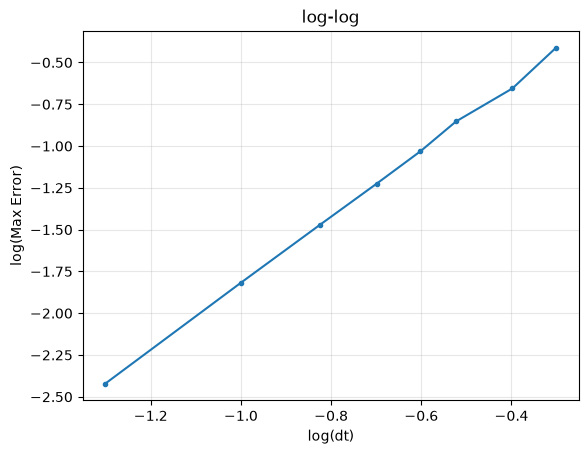

In [27]:
# second-order
logx = np.log10(dt_list)
logy = np.log10(max_error_suzuki)
loglog_slope=np.polyfit(logx, logy, deg=1)[0]
print("Slope =", loglog_slope)

plt.title("log-log")
plt.xlabel("log(dt)")
plt.ylabel("log(Max Error)")
plt.grid(alpha=0.3)
plt.plot(logx, logy, marker=".")
plt.show()

This time, the slope is very close to 2, which supports our previous explanation.

# Max Error vs. Total Amount of Two-Qubit Gates

To evaluate the trade-off between max error and the total number of two-qubit gates, we manually set the value of 0.05 as the threshold of minimum acceptable error, and then compare the minimum number of two-qubit gates (or the smallest possible $\Delta t$ required) to ensure that the error is less than or equal to this specified value. In this case, we say the results are "trustworthy" if the max error reaches this goal.

The code below plots the max error in $x$ magnetization  and total amount of two-qubit gates for different values of $\Delta t$ on the same graph using two different y-axes to provide a direct visual comparison. The values of the first-order Lie-Trotterization are shown as curves in warm colors (red and orange) and the values of the second-order Suzuki-Trotterization are shown as curves in cold colors (blue and green).

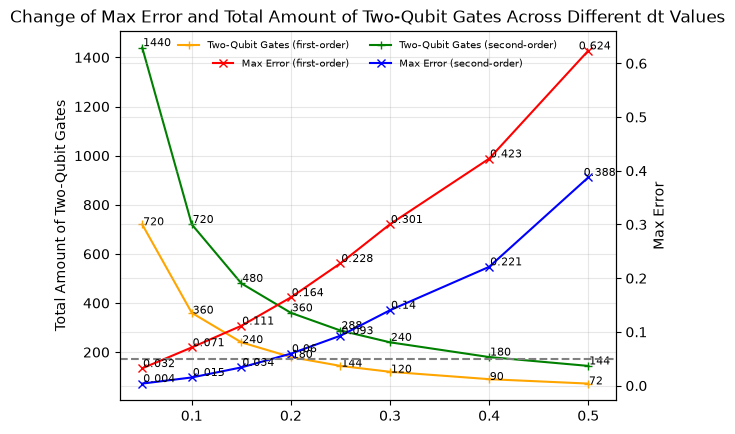

In [28]:
fig, ax1 = plt.subplots()
plt.title("Change of Max Error and Total Amount of Two-Qubit Gates Across Different dt Values")

# first-order amount of two-qubit gates (shown in orange)
ax1.plot(dt_list, two_qubit_gates_lie, marker='+', color='orange', label='Two-Qubit Gates (first-order)')
ax1.set_ylabel("Total Amount of Two-Qubit Gates")
ax1.grid(alpha=0.3)
#label values
texts = [ax1.text(x, y, y, fontsize=8) for x, y in zip(dt_list, two_qubit_gates_lie)]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

# second-order amount of two-qubit gates (shown in green)
ax1.plot(dt_list, two_qubit_gates_suzuki, marker='+', color='green', label='Two-Qubit Gates (second-order)')
ax1.grid(alpha=0.3)
# label values
texts = [ax1.text(x, y, y, fontsize=8) for x, y in zip(dt_list, two_qubit_gates_suzuki)]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

ax2=ax1.twinx()

# first-order max error (shown in red)
ax2.plot(dt_list, max_error_lie, marker='x', color='red', label='Max Error (first-order)')
ax2.set_xlabel("dt")
ax2.set_ylabel("Max Error")
ax2.grid(alpha=0.3)
# label values
texts = [ax2.text(x, y, round(y, 3), fontsize=8) for x, y in zip(dt_list, max_error_lie)]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

# second-order max error (shown in blue)
ax2.plot(dt_list, max_error_suzuki, marker='x', color='blue', label='Max Error (second-order)')
ax2.grid(alpha=0.3)
# label values
texts = [ax2.text(x, y, round(y, 3), fontsize=8) for x, y in zip(dt_list, max_error_suzuki)]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

# the threshold of 0.05
ax2.axhline(0.05, ls="--", color="gray")

ax1.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, 1), ncol=2, frameon=False)
ax2.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=2, frameon=False)
plt.show()

We can clearly see that $\Delta t$ has a negative relationship with total amount of two-qubit gates while a positive relationship with max error in $x$ magnetization. This is intuitive because, with the total evolution time $T$ remaining constant, as $\Delta t$ decreases, the number of trotter steps increases, making the trotterization process more accurate. At the same time, a greater number of trotter steps means more single-step evolution gates need to be appended, so the total amount of two-qubit gates naturally increases. Therefore the trade-off appears.

To evaluate the accuracy and worthiness of the methods, we use the largest values of $\Delta t$ and the fewest total amount of two-qubit gates that result in a max error less than or equal to the threshold of 0.05 we set.

As we can see from the figure, for first-order Lie-Trotterization, to achieve a max error below the threshold of 0.05, $\Delta t$ must be 0.05, and in this case the total amount of two-qubit gates is 720. While for second-order Suzuki-Trotterization, $\Delta t$ can be as large as 0.15 to reach the same accuracy, and the total amount of two-qubit gates is only 480. So even though each Suzuki step is more expensive, it needs far fewer steps, and the extra cost per step doesn’t outweigh the benefit.

Therefore the conclusion is very clear: in our setup, the second-order Suzuki-Trotterization is the better option, both in step size and in total two-qubit gate count.

# Conclusion

In this notebook, we simulated the time evolution of the transverse-field Ising model with Trotterization, and studied about error scaling, the effects of step size $\Delta t$ on accuracy, the trade-off between max error and total amount of two-qubit gates, and how well does the second-order Suzuki-Trotterization perform.

We initially obtained second-order results for the error scaling in first-order Lie-Trotterization. Through derivation, we then found that for this specific initial state $| 00 \dots 0 \rangle$ and observable $M_z$, the first-order and second-order trotterization actually yield the same outcome. Afterward, we replaced the observable from $z$ magnetization with $x$ magnetization, and again carried out first-order Trotterized time evolution, successfully obtaining the expected first-order results. We then moved on to second-order Suzuki-Trotterization and obtained the expected second-order error scaling results, increasing the reliability of our explanation.

After that, we studied the effect of smaller Trotter sizes on the accuracy of the results, plotted the max error against the total number of two-qubit gates, and then compared the outcomes of first-order Lie-Trotterization and second-order Suzuki-Trotterization. As expected, smaller $\Delta t$ gives lower error, but it also comes with more Trotter steps and deeper circuits, so there is a clear trade-off between accuracy and depth. Comparing the two methods, second-order Suzuki-Trotter reaches our error threshold of 0.05 with a larger $\Delta t$ and fewer two-qubit gates (480 vs. 720 for first-order Lie-Trotter), so in our setup the higher-order formula is a better method.

# References

[1] IBM Quantum, LieTrotter, Qiskit API Documentation, https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.2/qiskit.synthesis.LieTrotter